In [1]:
import numpy as np
from scipy.linalg import expm
import matplotlib as mpl
import matplotlib.pyplot as plt
import qutip as qt
import pandas as pd

In [2]:
# --- LaTeX rendering ---
mpl.rcParams['text.usetex'] = False# Set True only for final article figures (assuming some LaTeX compiler like MikTex or TeXLive installed)
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['DejaVu Serif']#Set ['Computer Modern Roman'] only for final article figures
mpl.rcParams['font.size'] = 11
mpl.rcParams['mathtext.fontset'] = 'cm'

# --- Lines ---
mpl.rcParams['lines.linewidth'] = 2.0

# --- Axes labels ---
mpl.rcParams['axes.labelsize'] = 16
mpl.rcParams['axes.titlesize'] = 16
mpl.rcParams['axes.linewidth'] = 1.0

# --- Ticks (LaTeX-style look) ---
mpl.rcParams['xtick.labelsize'] = 16
mpl.rcParams['ytick.labelsize'] = 16
mpl.rcParams['xtick.direction'] = 'in'
mpl.rcParams['ytick.direction'] = 'in'
mpl.rcParams['xtick.top'] = True
mpl.rcParams['ytick.right'] = True

# --- Legend ---
mpl.rcParams['legend.fontsize'] = 12
mpl.rcParams['legend.frameon'] = True

# --- Figure ---
mpl.rcParams['figure.figsize'] = (8, 5)
mpl.rcParams['figure.dpi'] = 100

In [27]:
Thrlev = False

Krt = True
#Pronto = False

#datfile = pd.read_csv('Data/OptFieldKr_X_GATE_3levs_q03.csv')
#datfile = pd.read_csv('Data/OptFieldKr_Had_GATE_3levs_alp2.csv')
#datfile = pd.read_csv('Data/OptFieldKr_S_GATE_3levs_alp1c5.csv')
#datfile = pd.read_csv('Data/OptFieldKr_Gate_4levs_2fld_2penal.csv')
#datfile = pd.read_csv('Data/OptFieldKr_Had_GATE_4levs_IFsin.csv')
#datfile = pd.read_csv('Data/OptFieldKr_S_GATE_4levs.csv')
#datfile = pd.read_csv('Data/OptField_PINN_S_GATE_3L.csv')

if (Thrlev):
  if (Krt):
    datfileX = pd.read_csv('Data/OptFieldKr_GATE_3levs_q03.csv')
    datfileH = pd.read_csv('Data/OptFieldKr_Had_GATE_3levs_alp2.csv')
    datfileS = pd.read_csv('Data/OptFieldKr_S_GATE_3levs_alp1c5.csv')
    midgrid = (datfileX.iloc[:, 0]).to_numpy().copy()
  
  else:
    datfileX = pd.read_csv('Data/OptField_PINN_X_GATE_3L.csv')
    datfileH = pd.read_csv('Data/OptField_PINN_H_GATE_3L.csv')
    datfileS = pd.read_csv('Data/OptField_PINN_S_GATE_3L.csv')
    midgrid = (datfileX.iloc[:, 0]).to_numpy().copy()
    midgrid *= 10

else:
  if (Krt):
    datfileX = pd.read_csv('Data/OptFieldKr_Gate_4levs_2fld_2penal.csv')
    datfileH = pd.read_csv('Data/OptFieldKr_Had_GATE_4levs_IFsin.csv')
    datfileS = pd.read_csv('Data/OptFieldKr_S_GATE_4levs.csv')
    midgrid = (datfileX.iloc[:, 0]).to_numpy().copy()
  else:
    datfileX = pd.read_csv('Data/OptField_PINN_X_GATE_4L.csv')
    datfileH = pd.read_csv('Data/OptField_PINN_H_GATE_4L.csv')
    datfileS = pd.read_csv('Data/OptField_PINN_S_GATE_4L.csv')
    midgrid = (datfileX.iloc[:, 0]).to_numpy().copy()

ctrlX = (datfileX.iloc[:, 1:]).to_numpy().copy()
ctrlH = (datfileH.iloc[:, 1:]).to_numpy().copy()
ctrlS = (datfileS.iloc[:, 1:]).to_numpy().copy()
ctrl = np.hstack((ctrlX, ctrlH, ctrlS))

if (not Thrlev and (not Krt)):
  ctrl *= 2

Tf = midgrid[-1]
dt = midgrid[2]-midgrid[1]
N = len(midgrid)-2
tgrid = midgrid[1:] - 0.5*dt*np.ones(N+1)
tgrid[-1] = Tf
Nctrls = ctrlX.shape[1]

In [143]:
ctrl.shape

(501, 3)

In [28]:
if (Thrlev):
  dim = 3

  #Utgt = np.array([[0,1,0], [1,0,0], [0,0,1]], dtype=np.complex128)
  #List of initial and target states
  #psi0 = [(0.2*qt.basis(dim, 0) + 0.5*qt.basis(dim, 1)).unit().full(), (0.7*qt.basis(dim, 0) - 0.15*qt.basis(dim, 1)).unit().full()]
  #psi_tgt = [Utgt@psi0[i] for i in range(len(psi0))]

  E0 = 0.0
  E1 = 1.0
  E2 = 5.0
  Ω01 = 0.1
  Ω02 = 0.3
  Ω12 = 0.5
  H0 = np.array([[E0, 0, 0], [0, E1, 0],[0, 0, E2]], dtype=np.complex128)
  H1 = np.array([[0, Ω01, Ω02], [Ω01, 0, Ω12], [Ω02, Ω12, 0]], dtype=np.complex128)
  ctHams = np.stack([H1])
else:
  # Parâmetros do Transmon (em unidades de GHz, por exemplo)
  dim = 4  # Número de níveis
  f_q = 6.79  # Frequência de detuning do termo |3><3|
      
  # Hamiltoniano do Transmon (Duffing Oscillator)
  # H = f_q * a.dag() * a + (alpha/2) * a.dag() * a.dag() * a * a
  H0 = (f_q * qt.ket2dm(qt.basis(dim, 3))).full()
      
  # 1. Calcular Níveis de Energia
  #energies = H0.eigenenergies()

  # 2. Simulação de Evolução Temporal (Rabi Oscillation)
  # Vamos aplicar um drive ressonante com a transição 0 -> 1
  Nctrls = 2
  Omega = 0.5  # Força do drive (Rabi frequency) em GHz
  H1 = Omega * (qt.basis(dim, 0)*(qt.basis(dim, 2) + qt.basis(dim, 3)).dag() + (qt.basis(dim, 2) + qt.basis(dim, 3))*qt.basis(dim, 0).dag()).full()
  H2 = Omega * (qt.basis(dim, 1)*(qt.basis(dim, 2) - qt.basis(dim, 3)).dag() + (qt.basis(dim, 2) - qt.basis(dim, 3))*qt.basis(dim, 1).dag()).full()
  ctHams = np.stack([H1, H2])

Run this for the 5-level system.

In [ ]:
# Parâmetros do Transmon (em unidades de GHz, por exemplo)
dim = 5  # Número de níveis
f_q = 5.0  # Frequência do qubit (0 -> 1) em GHz
alpha = -0.3  # Anarmonicidade em GHz (típico para transmons)

# Operadores
a = qt.destroy(dim)
adag = a.dag()
    
# Hamiltoniano do Transmon (Duffing Oscillator)
# H = f_q * a.dag() * a + (alpha/2) * a.dag() * a.dag() * a * a
H0 = (f_q * adag * a + (alpha / 2.0) * adag * adag * a * a).full()
    
# 1. Calcular Níveis de Energia
#energies = H0.eigenenergies()

# 2. Simulação de Evolução Temporal (Rabi Oscillation)
# Vamos aplicar um drive ressonante com a transição 0 -> 1
Nctrls = 2
Omega = 0.5  # Força do drive (Rabi frequency) em GHz
H1 = (Omega * (a + adag)).full()
H2 = (Omega * 1j*(adag - a)).full()
ctHams = np.stack([H1, H2])

# Hamiltoniano total
#H = [H0, [H_drive, 'sin(wd * t)']]
#args = {'wd': f_q}
    
# Estado inicial: fundamental |0>
#psi0 = [qt.basis(dim, 0).full(), qt.basis(dim, 1).full()]
# Target state
#psi_tgt = [qt.basis(dim, 1).full(), qt.basis(dim, 0).full()]

Evolve the initial/s state/s.

In [98]:
# Declare the array to store the states and set the initial value.
#Indices correspond to (initial state, element of the state vector, time grid points)
psi = np.zeros((len(psi0), dim, N + 1), dtype=complex)
for i in range(psi.shape[0]):
    psi[i, :, 0] = psi0[i].flatten()

# Evolve under the guess control field
for i in range(N):
    Htot = H0.copy()
    for j in range(Nctrls):
        Htot += ctrl[i + 1, j] * ctHams[j]
    U = expm(-1j * Htot * dt)
    for k in range(len(psi0)):
        psi[k, :, i + 1] = (U @ psi[k, :, i].T).T

Evolve a set of initial Haar random states (uniformly distributed on the Bloch sphere).

In [29]:
allfids = np.zeros((N+1, 3))
allleakdyns = np.zeros((N, 3))
leakpops = np.zeros(3)
nsamp = 500# Number of random states to evolve
psi0 = [( (np.random.randn() + 1j*np.random.randn())*qt.basis(dim, 0) + (np.random.randn() + 1j*np.random.randn())*qt.basis(dim, 1)).unit().full() for _ in range(nsamp)]

if (Thrlev):
    UX = np.array([[0,1,0], [1,0,0], [0,0,1]], dtype=np.complex128)
    UH = np.array([[np.sqrt(0.5), np.sqrt(0.5),0], [np.sqrt(0.5), -np.sqrt(0.5),0], [0,0,1]], dtype=np.complex128)
    US = np.array([[1,0,0], [0,1j,0], [0,0,1]], dtype=np.complex128)
else:
    UX = np.array([[0,1,0,0], [1,0,0,0], [0,0,1,0], [0,0,0,1]], dtype=np.complex128)
    UH = np.array([[np.sqrt(0.5), np.sqrt(0.5),0,0], [np.sqrt(0.5), -np.sqrt(0.5),0,0], [0,0,1,0], [0,0,0,1]], dtype=np.complex128)
    US = np.array([[1,0,0,0], [0,1j,0,0], [0,0,1,0], [0,0,0,1]], dtype=np.complex128)

Gateslist = [UX, UH, US]
for m,Utgt in enumerate(Gateslist):
    avrfid = np.zeros(N+1)
    leakage_dyn = np.zeros(N)
    int_pop = 0.
    psi_tgt = [(Utgt @ psi0[i].flatten().T).T for i in range(nsamp)]

    for i in range(nsamp):
        I_i = 0.0
        psi = psi0[i].flatten()
        avrfid[0] += np.abs(psi.conj().T @ psi_tgt[i])**2
        p0 = np.sum([np.abs(psi[-1-l])**2 for l in range(UX.shape[0]-2)])
        for k in range(N):
            Htot = H0.copy()
            for j in range(Nctrls):
                Htot += ctrl[k + 1, j + Nctrls*m] * ctHams[j]
            
            U = expm(-1j * Htot * dt)
            psi = (U @ psi.T).T
            avrfid[k+1] += np.abs(psi.conj().T @ psi_tgt[i])**2
            pk = np.sum([np.abs(psi[-1-l])**2 for l in range(UX.shape[0]-2)])
            leakage_dyn[k] += pk

            # Simpson weights
            if k == 0:
                I_i += p0 + pk
            elif k % 2 == 1:
                I_i += 4 * pk
            else:
                I_i += 2 * pk

        I_i *= dt / 3
        int_pop += I_i

    avrfid /= nsamp
    int_pop /= nsamp
    leakage_dyn /= nsamp

    allfids[:, m] = avrfid
    allleakdyns[:, m] = leakage_dyn
    leakpops[m] = int_pop

In [6]:
def plot_population(tgrid, psi, tlt):
    basis = [qt.basis(dim, k).full() for k in range(dim)]
    ocs = np.zeros((N + 1, dim))
    for i in range(N + 1):
        for j in range(dim):
            ocs[i, j] = np.abs(np.vdot(basis[j].flatten(), psi[:, i]))**2
    print(f'Occupancies at final time: {ocs[-1,:]}')
    fig, ax = plt.subplots()
    for k in range(dim):   
        ax.plot(tgrid, ocs[:,k], label=fr"$|{k}\rangle$")
    ax.legend(loc='center left')
    ax.set_xlabel('Time [ns]')
    ax.set_ylabel('Population')
    ax.set_title(tlt)
    plt.show(fig, block=False)
    return fig

Occupancies at final time: [1.49923730e-03 9.97005731e-01 1.55496801e-05 1.47948229e-03]


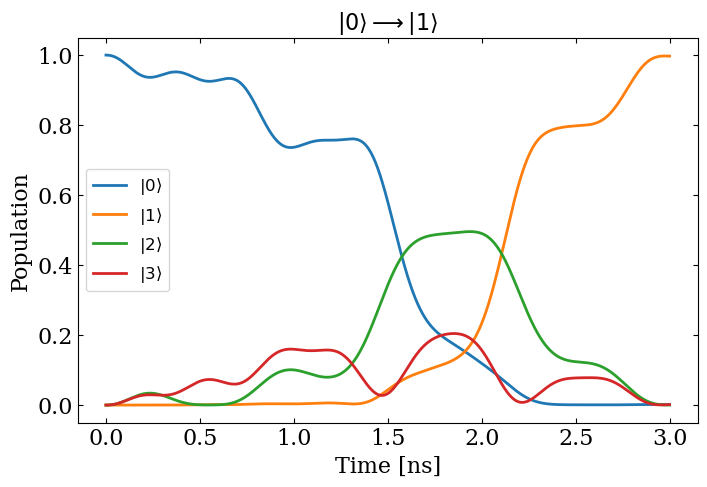

In [99]:
inlev = 0
fig = plot_population(tgrid, psi[inlev, :, :], fr'$|{inlev}\rangle \longrightarrow |1\rangle$')

In [22]:
# Save the plot as a PDF file
fig.savefig("Figures/PopsKr_1toi1_4-lev.pdf", bbox_inches='tight', format="pdf") # 'bbox_inches="tight"' removes extra whitespace

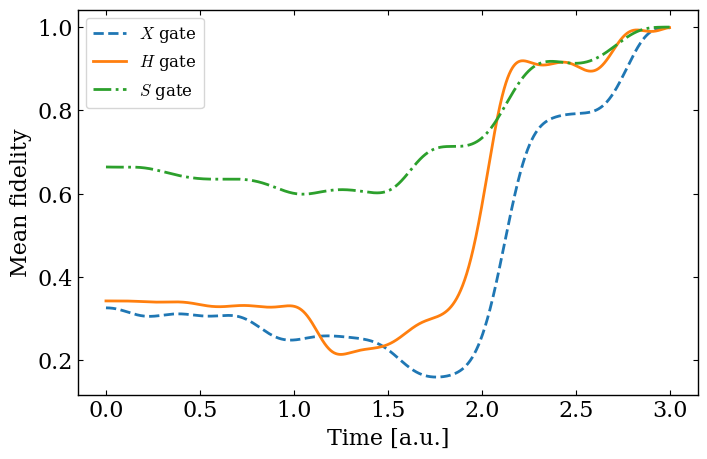

In [30]:
fig, ax = plt.subplots()
ax.plot(tgrid, allfids[:,0],'--', label = r"$X$ gate")
ax.plot(tgrid, allfids[:,1], label = r"$H$ gate")
ax.plot(tgrid, allfids[:,2],'-.', label = r"$S$ gate")
xlab = 'Time [ns]' if Thrlev else 'Time [a.u.]'
ax.set_xlabel(xlab)
ax.set_ylabel('Mean fidelity')
plt.legend()
plt.show(fig, block=False)

In [168]:
# Save the plot as a PDF file
fig.savefig("Figures/MeanFidelity_FourLevel_PINN.pdf", bbox_inches='tight', format="pdf")

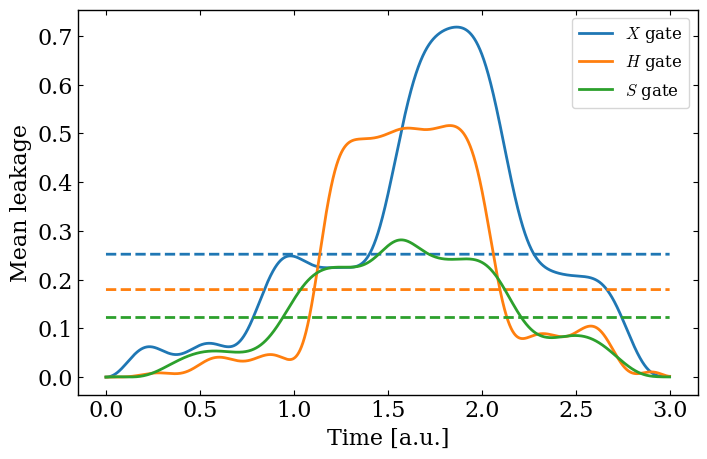

In [31]:
figleak, ax = plt.subplots()
ax.plot(tgrid[1:], allleakdyns[:,0], label = r"$X$ gate")
ax.plot(tgrid[1:], (leakpops[0]/Tf)*np.ones_like(tgrid[1:]), '--', color='C0')
ax.plot(tgrid[1:], allleakdyns[:,1], label = r"$H$ gate")
ax.plot(tgrid[1:], (leakpops[1]/Tf)*np.ones_like(tgrid[1:]), '--', color='C1')
ax.plot(tgrid[1:], allleakdyns[:,2], label = r"$S$ gate")
ax.plot(tgrid[1:], (leakpops[2]/Tf)*np.ones_like(tgrid[1:]), '--', color='C2')
xlab = 'Time [ns]' if Thrlev else 'Time [a.u.]'
ax.set_xlabel(xlab)
ax.set_ylabel('Mean leakage')
plt.legend()
plt.show(figleak, block=False)

In [163]:
figleak.savefig("Figures/Leakage_PINN_ALL_3lev.pdf", bbox_inches='tight', format="pdf")

In [32]:
leakpops/Tf

array([0.25215796, 0.17959327, 0.12228598])

In [33]:
allfids[-1,:]

array([0.99762111, 0.99828263, 0.99961308])

In [35]:
import pandas as pd

In [39]:
merged = np.vstack((tgrid[1:].T, allfids, allleakdyns))    
df_from_numpy = pd.DataFrame(merged.T)

# Exporting the NumPy-based DataFrame
df_from_numpy.to_csv('Data/fids_leak_Kr_Gate_4levs.csv', index=False, header=['Time'] + [f"Fid"] + [f"Leak"])

ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 1, the array at index 0 has size 10000 and the array at index 1 has size 3

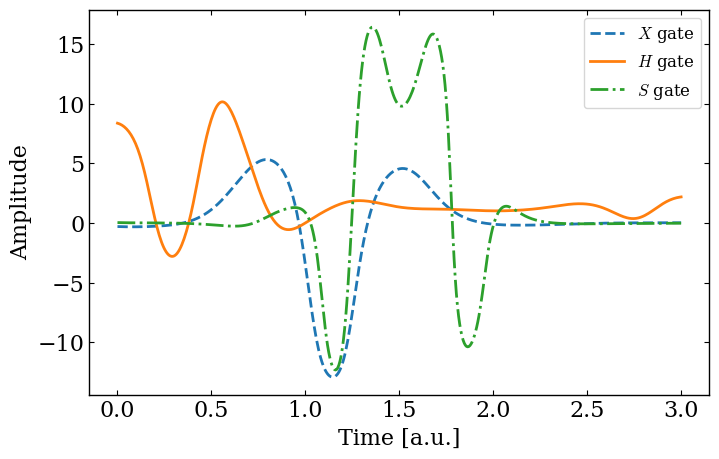

In [11]:
nct = 1
fig, ax = plt.subplots()
ax.plot(midgrid, ctrl[:,nct], '--', label="$X$ gate")#'$\\Omega_p$')
ax.plot(midgrid, ctrl[:,Nctrls + nct], label="$H$ gate")#'$\\Omega_m$')
ax.plot(midgrid, ctrl[:,2*Nctrls + nct], '-.', label="$S$ gate")#'$\\Omega_m$')
#ax.plot(midgrid, ctrl[:,0], label='$\\Omega_p$')
#ax.plot(midgrid, ctrl[:,1], label='$\\Omega_m$')
xlab = 'Time [ns]' if Thrlev else 'Time [a.u.]'
ax.set_xlabel(xlab)
ax.set_ylabel('Amplitude')
#ax.set_title('Optimized control field')
#ax.set_xlim(Tf-100*dt, Tf)
plt.legend()
plt.show(fig, block=False)

In [12]:
fig.savefig("Figures/OptFlds_PINN_Sfield_ALL_4lev.pdf", bbox_inches='tight', format="pdf") # 'bbox_inches="tight"' removes extra whitespace

Now, plot the convergence of the algorithm.

In [16]:
#datconverg = pd.read_csv('Data/JT_iters_Kr_Gate_4levs.csv')
#datconverg = pd.read_csv('Data/JT_iters_Kr_S_Gate_3levs_alp1c5.csv')
#datconverg = pd.read_csv('Data/JT_iters_Kr_Had_Gate_4levs_IFsin.csv')
datconverg = pd.read_csv('Data/JT_iters_Kr_S_Gate_4levs.csv')
Jrel = (datconverg.iloc[:, 0]).to_numpy().copy()

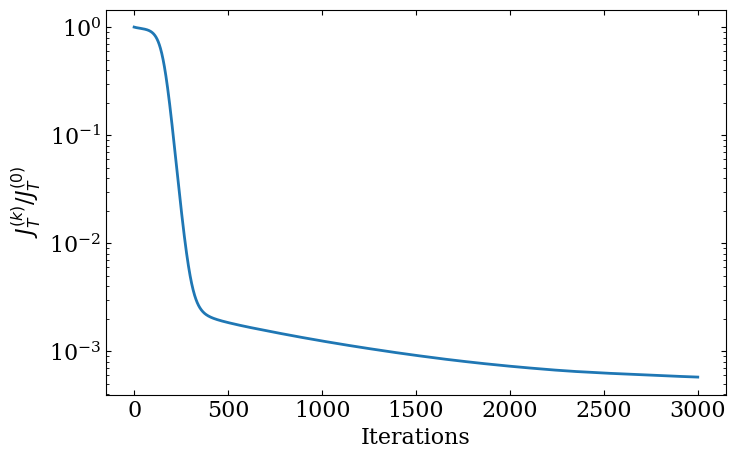

In [17]:
fig, ax = plt.subplots()
ax.plot(Jrel)
ax.set_xlabel('Iterations')
ax.set_ylabel(r'$J_T^{(k)}/J_T^{(0)}$')
ax.set_yscale('log')
plt.show(fig, block=False)

In [18]:
fig.savefig("Figures/JT_Kr_S_4lev.pdf", bbox_inches='tight', format="pdf") # 'bbox_inches="tight"' removes extra whitespace